In [31]:
import sys

if sys.version_info[0] + 0.1 * sys.version_info[1] < 3.6:
    raise Exception("Must be using Python 3.6+ version")

In [32]:
%matplotlib inline
sys.path.append("..")

from plotly.subplots import make_subplots
import plotly.graph_objects as go

import numpy as np

import wavelet_transform.utils.training_data as train
from wavelet_transform.postprocess import plotting as plot
import wavelet_transform.wpt.inverse_transform as inv
from wavelet_transform.utils.extensions import fft, psd, to_dB, eng_form_plot, trim_data
from wavelet_transform.utils.machine_learning import fit_and_evaluate, train_k_means, assess_parameter
import wavelet_transform.utils.kmeans_results as results
from wavelet_transform.utils.preprocessing import preprocess
from wavelet_transform.utils.save_plots import save_figure
from wavelet_transform.utils.new_bubbledynamics import BubbleDynamics as BD

result_id is used to store the results in a file that can be found using results.get_data(result_id)

In [33]:
saveflag = False

Set up parameters for incident wave

In [34]:
pac = 0.05e6  # the amplitude of the sine wave in Pa
f0_frequency = 2 * 1e6   # insonation frequency (Hz)
period = 1 / f0_frequency  # the period of the acoustic wave at the fundamental frequency 
fs = f0_frequency * 1e3   # sampling rate to generate the time vector

time_delay = 4 * period   # time delay, t1
pulse_width = 1000 * period  # pulse width, W = 1 / Q
phase_initial = 0  #-0.325 * period  # tau
phase_shift = 0  # np.pi / 4  # phi
no_harmonics = 1  # k

R_init = 1e-6  # initial bubble radius in meters
Rdot_init = 0  # initial bubble's wall velocity in m/s

r_measure = 1e-4  # distance from the centre of bubble which radiated pressure (acoustic emission from bubble) is calculated over time

no_cycle = 10  # no. of cycles of the sine wave
deltat = 1.0 / fs
tmax = no_cycle * period
time = np.arange(
    0.0, tmax, deltat
)  # time vector for computing the sine wave, in seconds

Initialise bubble dynamics object

In [35]:
BD_obj = BD(
    R_init=R_init,
    Rdot_init=Rdot_init,
    frequency=f0_frequency,
    time=time,
    deltat=deltat,
)

Add incident wave

In [36]:
BD_obj.initialize()
BD_obj.add_pac_wave(
    f0_frequency,
    pac,
    time_delay,
    pulse_width,
    phase_initial,
    phase_shift,
    no_harmonics
)

Add acd pulse

In [37]:
acd_freq = 10e6
acd_pac = 0.05e6
acd_time_delay = 4e-6
acd_pulse_width = 1 / acd_freq
BD_obj.add_pac_wave(acd_freq, acd_pac, acd_time_delay, acd_pulse_width, 0, 0, 1)

Solve bubble dynamics

In [38]:
BD_obj.solver()

Get radiated pressure from bubble dynamics

In [61]:
BD_obj.calculate_p_radiated_vokurka(r_measure)
fig = go.Figure()
fig.add_trace(go.Scatter(x=BD_obj.time, y=BD_obj.p_radiated_vokurka, mode="lines"))
fig.update_layout(
    title="radiated pressure",
    xaxis_title="time/s",
    yaxis_title="pressure/Pa"
)

Set up wavelet transform

In [40]:
# Parameters for the wavelet transform
wavelet = "db36"
levels = 12  # set to None to use max-level transform
mode = "symmetric"
use_min_entropy = True
min_level = 8
freq_threshold = 1
no_clusters = 10

Plotting radiated pressure

In [41]:
# Plot ACD data
data = BD_obj.p_radiated_vokurka
data = train.add_noise(data, 30)
fig = go.Figure()
t_plot = time
fig.add_trace(
    go.Scatter(x=t_plot, y=data, mode='lines', name='data')
)

fig.update_layout(
    xaxis=dict(title='Time [s]'),
    yaxis=dict(title='Amplitude [DL]'),
    title="radiated pressure"
)
fig.show()

In [42]:
# Normalise
data_processed = preprocess(data, window=False)

In [43]:
# Trim the array down to a start and end time
# t_lims = (40e-6, 160e-6)
# data_trim, t_plot = trim_data(data, t_plot, t_lims, return_time=True)
# data_processed = preprocess(data_trim)

In [44]:
# Plot generated data
# fft_data, freq = fft(data_processed, sampling_rate, frequency)
fft_lim = 10
def plot_fft(data, sampling_rate, frequency):
    fft_data, freq = fft(data, sampling_rate, frequency)
    
    # plot sound wave and fft
    fig = make_subplots(rows=1, cols=1)

    fig.add_trace(
        go.Scatter(x=freq, y=to_dB(np.abs(fft_data)), mode="lines", name="fft - amp"),
        row=1,
        col=1,
    )
    
    fig.update_layout(
        height=500,
        width=1000,
        font_size=20,
        xaxis1=dict(title="Freq [f/f<sub>0</sub>]", range=[0, fft_lim]),
        yaxis1=dict(title="Amplitude [dB]", range=[-40, 40]), 
        legend=dict(x=0.8, y=1, font=dict(size=20)),
        plot_bgcolor="white",     
    )
    fig.update_xaxes(showgrid=True, gridwidth=1, gridcolor='lightgrey')
    fig.update_yaxes(showgrid=True, gridwidth=1, gridcolor='lightgrey')        
    fig.show()
    return fig

In [45]:
sampling_rate = fs
frequency = f0_frequency

In [46]:
fig = plot_fft(data_processed, sampling_rate, frequency)
if saveflag is True:
    save_figure(fig, f"{result_id}_data")

## Wavelet transform

In [47]:
wpt_df, tr_obj = train.generate_training_data(
    data_processed, levels, wavelet, mode, 
    include_tr_obj=True, min_entropy=use_min_entropy,
    min_level=min_level, freq_threshold=freq_threshold
)

## Training

In [48]:
# k-means parameters
kmeans_params = {
    "init": "k-means++",
    "n_init":10,
    "max_iter":100,
    "tol":1e-8,
    "verbose":0,
    "algorithm":"lloyd",
}

# training data
classifying_metrics = [
    "log average energy",
    "kurtosis",
    # "crest factor",
    # "level entropy",
    "spectral entropy",
    "average energy",
    # "skewness"
]
# Set to no_clusters to None to select optimal number of clusters by silhouette score
use_inverse_metrics = False
scale_data = "standard"
if use_inverse_metrics is True:
    inv_tr_obj = inv.InverseTransform(tr_obj)  # Use info from inverse transform object instead
    wpt_df_train = inv_tr_obj.info(leaf_nodes=True, freq_threshold=freq_threshold)
else:
    wpt_df_train = wpt_df.copy()

In [49]:
data_train, labels, data_train_normalised, centers, scaler, kmeans = train_k_means(
    wpt_df_train, 
    classifying_metrics, 
    no_clusters=no_clusters, 
    kmeans_params=kmeans_params, 
    scale_data=scale_data
)

In [50]:
ordered_centers, ordered_labels = plot.relabel(labels, centers, "average energy")

## Save results

In [51]:
if saveflag == True:
    additional_params = {
        "raw_data": data,
        "driving frequency": frequency,
    }

    results.save_data(
        result_id, data_train, tr_obj, centers, labels, 
        sampling_rate, freq_threshold, **additional_params
    )

## Plot results

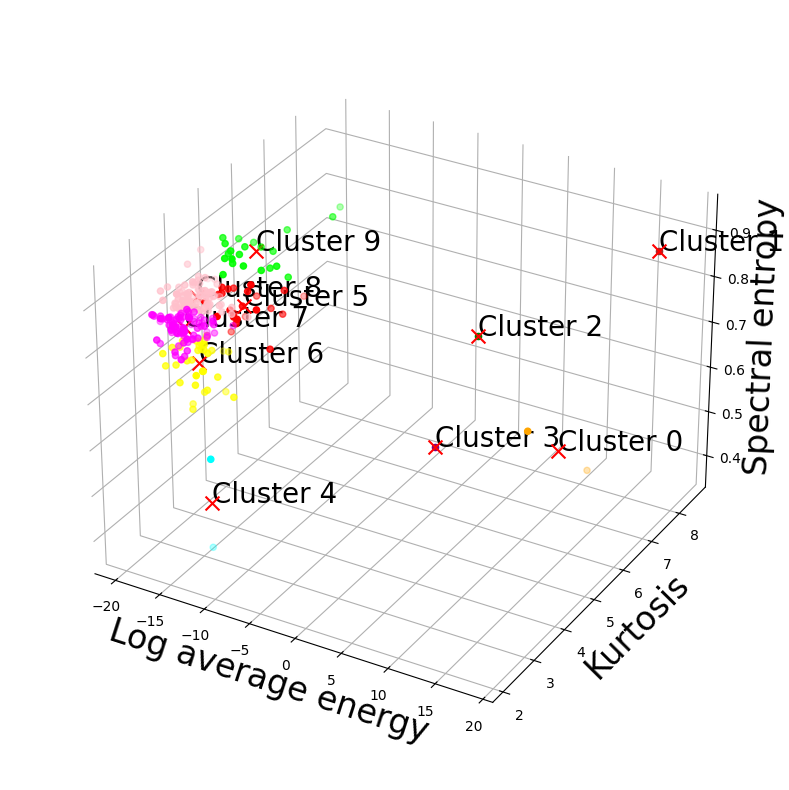

In [52]:
fig = plot.plot_clustering(
    data_train, 
    ordered_centers,
    ordered_labels, 
    [classifying_metrics[i] for i in [0, 1, 2]], 
    title=None
)

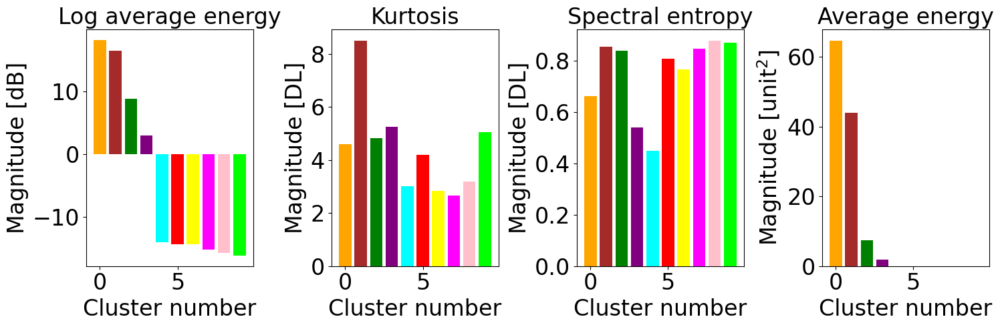

In [53]:
# Plot centroid metrics
# xaxis_ticks_labels = dict((i, f"Clu÷ster {i}") for i in range(len(centers)))
fig = plot.plot_centers(classifying_metrics, ordered_centers) #, label_map=xaxis_ticks_labels)

In [54]:
from scipy import signal
import matplotlib.pyplot as plt

def stft_plt(data, frequency, period, sampling_rate, tick_size, fsize):
    fig, ax = plt.subplots()
    fig.set_size_inches(18, 9)
    f_stft, t_stft, mag_stft = signal.stft(data, sampling_rate, nperseg=2**11, detrend=False, scaling='spectrum')
    stft_plt = ax.pcolormesh(t_stft/period, f_stft/frequency, 20*np.log10(np.abs(mag_stft)), vmin=-50, vmax=10, shading='gouraud')
    ax.set_ylabel("$f / f_0$ [DL]", fontsize=fsize)
    ax.set_xlabel("t/T [DL]", fontsize=fsize)  # noqa
    ax.set_title('STFT - spectrum', fontsize=fsize)
    ax.set_ylim([0,10]) 
    plt.xticks(fontsize=tick_size)
    plt.yticks(np.arange(0,15),np.arange(0,15),fontsize=tick_size)
    cbar_label = ("Magnitude [dB]")
    fig.tight_layout()
    cbar = fig.colorbar(stft_plt, pad=0.01)
    cbar.ax.tick_params(labelsize=tick_size)
    cbar.set_label(label=cbar_label, size=fsize)
    plt.show()

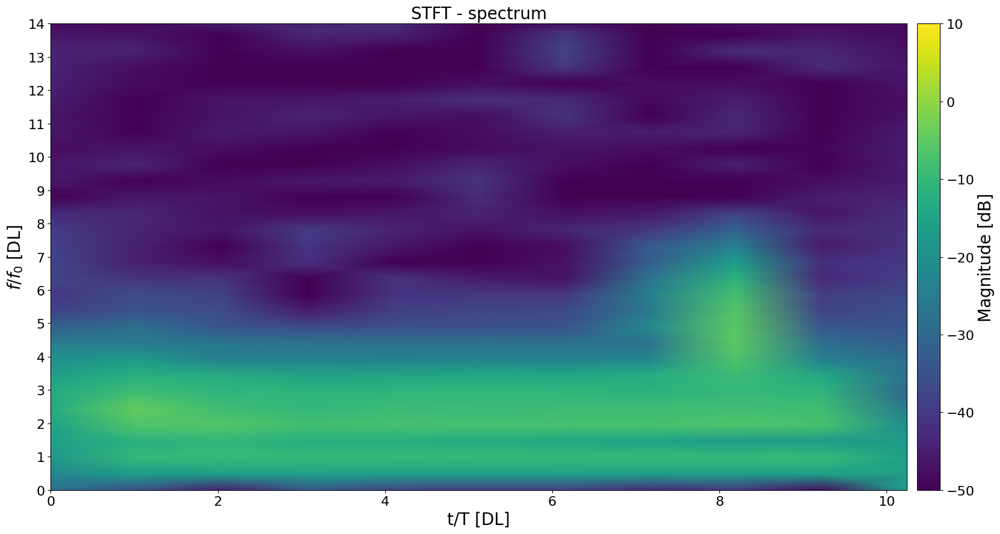

In [55]:
stft_plt(data_processed, frequency, period, sampling_rate, 16, 20)

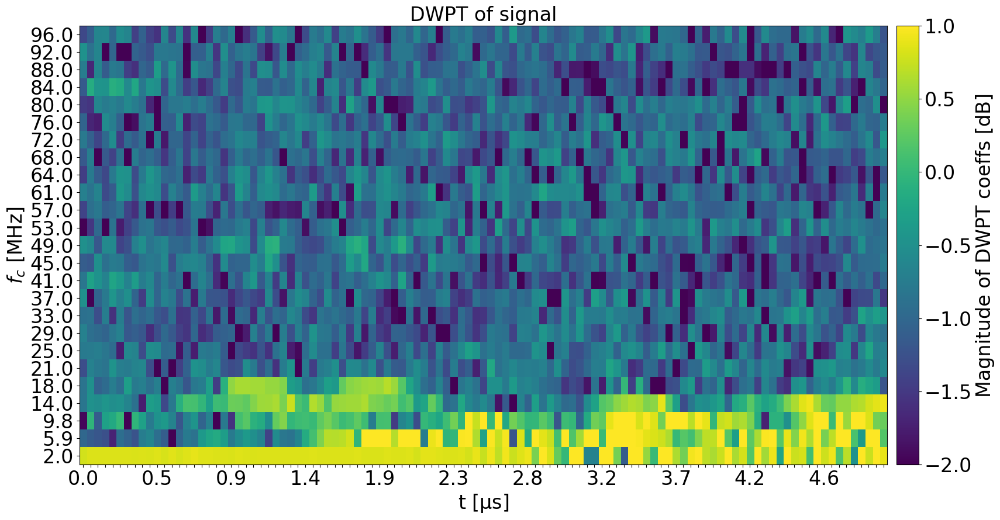

In [56]:
tr_obj.calc_frequencies(sampling_rate)
fig = plot.heisenberg(
    tr_obj, t_plot[-1], max_freq=freq_threshold/10, padding="repeat", use_log_scale=True,
    vmin=-2, vmax=1, color_map='viridis'
)

# tr_obj.plot_tree(
#     node_size="average energy",
#     node_colour=list(labels), 
#     freq_threshold=freq_threshold, 
#     order="natural",
#     sampling_rate=sampling_rate,
#     show_frequency=False,
# )

In [57]:
# Set clusters to None to plot all of them, otherwise, plot a list of int
fig = plot.plot_fft_by_group(
    tr_obj, ordered_labels, sampling_rate,
    clusters=None, xlims=[0,10], 
    fundamental_freq=frequency,
    freq_threshold=freq_threshold, fig_height=350,
    plot_full_reconstruction=False    
)

fig = plot.plot_reconstructions_by_group(
    tr_obj, ordered_labels, t_plot, freq_threshold
)

In [58]:
from wavelet_transform.postprocess.plotting import get_reconstructions_by_group
import plotly.graph_objects as go
recs = get_reconstructions_by_group(tr_obj, ordered_labels, freq_threshold)
fig = go.Figure()
fig.add_trace(
    go.Scatter(
        x=t_plot,
        y=sum(recs),
        mode="lines",
        name="Signal with freq thresholding",
    )
)
fig.add_trace(
    go.Scatter(
        x=t_plot,
        y=tr_obj.data,
        mode="lines",
        name="Orignial signal"
    )
)


In [59]:
import wavelet_transform.wpt.inverse_transform as inv
import matplotlib.pyplot as plt

# Add number to plot_centres to plot reconstructions of all nodes belonging to the cluster
plot_centres = [1]

# Loop through nodes and plot with plotly
for i, (node, assignment) in enumerate(zip(tr_obj.get_leaf_nodes(freq_threshold=freq_threshold), ordered_labels)):
    # Create a figure object
    fig = go.Figure()

    if assignment in plot_centres:
        print("spectral entropy:", node.spectral_entropy)
        rec = inv.inv_dwpt(tr_obj, node.level, nodes=node)
        psd_rec, freq = psd(rec, sampling_rate, frequency)
        
        # Create a plot for the Power Spectral Density (PSD)
        fig.add_trace(go.Scatter(
            x=freq, 
            y=to_dB(psd_rec),
            mode='lines',
            name=f"Node {i} PSD"
        ))
        
        # Set frequency range (x-axis limit)
        fig.update_xaxes(range=[0, 10])

        # Set title and axes labels
        fig.update_layout(
            title=f"Frequency range: {np.divide(node.frequency_range, frequency)} (normalised by f0)",
            xaxis_title="Frequency (Hz)",
            yaxis_title="Power Spectral Density (dB)"
        )

        # Create a plot for the reconstructed signal
        fig2 = go.Figure()
        fig2.add_trace(go.Scatter(
            x=t_plot, 
            y=rec,
            mode='lines',
            name=f"Node {i} Signal"
        ))

        # Set title for the reconstructed signal plot
        fig2.update_layout(
            title=f"Reconstructed Signal for Node {i}",
            xaxis_title="Sample Index",
            yaxis_title="Amplitude"
        )

        # Show the plots
        fig.show()
        fig2.show()


spectral entropy: 0.8562839058885168


In [60]:
import wavelet_transform.utils.statistical_features as sf

kurt_thrsh = 3
rec_high_kurt, rec_low_kurt = plot.get_reconstructions_by_threshold(
    tr_obj, feature="kurtosis", threshold=kurt_thrsh, freq_threshold=freq_threshold
)

fig = go.Figure()
fig.add_trace(go.Scatter(
    # x=freq, 
    y=tr_obj.data,
    mode='lines',
    name="original signal"
))
fig.add_trace(go.Scatter(
    # x=freq, 
    y=rec_high_kurt,
    mode='lines',
    name="high kurtosis reconstruction (wavelet coefficient kurtosis)"
))
fig.add_trace(go.Scatter(
    # x=freq, 
    y=rec_low_kurt,
    mode='lines',
    name="low kurtosis reconstruction (wavelet coefficient kurtosis)"
))
fig.show()

rec_high_kurt2, rec_low_kurt2 = plot.get_reconstructions_by_threshold(
    tr_obj, feature=sf.kurtosis, threshold=kurt_thrsh, freq_threshold=freq_threshold
)
fig2 = go.Figure()
fig2.add_trace(go.Scatter(
    # x=freq, 
    y=tr_obj.data,
    mode='lines',
    name="original signal"
))
fig2.add_trace(go.Scatter(
    # x=freq, 
    y=rec_high_kurt2,
    mode='lines',
    name="high kurtosis reconstruction (reconstruction kurtosis)"
))
fig2.add_trace(go.Scatter(
    # x=freq, 
    y=rec_low_kurt2,
    mode='lines',
    name="low kurtosis reconstruction (reconstruction kurtosis)"
))
fig2.show()